In [1]:
import argparse
import scanpy as sc
import scimap as sm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
import anndata as ad
from sklearn.decomposition import NMF



Running SCIMAP  2.3.5


/root/miniconda3/envs/scimap/lib/python3.10/site-packages/mpl_scatter_density/__init__.py:4: UserWarning:

pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.



In [49]:

adata = sc.read("/mnt/e/af HIP.h5ad")
adata.obsm['spatial'] = adata.obsm['X_spatial']

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

In [3]:
adata.obsm['spatial']

array([[ 4384.17089844, 20912.72412109],
       [ 4350.80859375, 21072.87817383],
       [ 4344.00488281, 21066.05639648],
       ...,
       [ 6635.31738281, 13621.38867188],
       [ 6660.38183594, 13464.53808594],
       [ 7450.93652344, 13691.94824219]])

In [51]:
adata.obs['batch']=1
adata.obs['X_centroid'] = adata.obsm['spatial'][:, 0]  #
adata.obs['Y_centroid'] = adata.obsm['spatial'][:, 1]  # 
adata= sm.tl.spatial_count(adata, phenotype='Cell_Anno', #
                            method='radius', radius=150, label='spatial_count',imageid='batch')

Identifying neighbours within 150 pixels of every cell


In [58]:

adata = ad.AnnData(X=adata.uns['spatial_count'],obs = adata.obs,uns = adata.uns)

adata.var.index = adata.uns['spatial_count'].columns

adata.uns['spatial_count'] = adata.uns['spatial_count'].loc[adata.obs.index,:]

nmf = NMF(n_components=5, init='random', random_state=42)

#nmf_features = nmf.fit_transform(adata.uns['spatial_count'])

In [7]:


adata.obsm['NMF'] = nmf_features

sc.pp.neighbors(adata, use_rep='NMF')

sc.tl.leiden(adata, resolution=0.05, key_added='neighborhood_clusters')




/tmp/ipykernel_651/88143997.py:5: FutureWarning:

In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.



In [18]:
adata

In [41]:
adata1 = adata[adata.obs['Hip'] == 'niche_3']#######

In [42]:
###
# 
def calculate_gene_percentage(adata):
    # 
    if hasattr(adata.X, 'toarray'):
        # 
        gene_sums = np.array(adata.X.sum(axis=0)).flatten()
    else:
        # 
        gene_sums = adata.X.sum(axis=0)
    
    # 
    total_expression = gene_sums.sum()
    
    # 
    gene_percentages = (gene_sums / total_expression) * 100
    
    # 
    result_df = pd.DataFrame({
        'gene': adata.var_names,
        'total_expression': gene_sums,
        'percentage': gene_percentages
    })
    
    # 
    result_df = result_df.sort_values('percentage', ascending=False)
    
    return result_df

# 
gene_percentage_df = calculate_gene_percentage(adata1)
print(gene_percentage_df)

         gene  total_expression  percentage
5  Neurons_EX        155.730522   82.397102
0       Astro         12.381355    6.550981
1          EC          6.614427    3.499697
8       Oligo          4.333624    2.292923
6  Neurons_IN          3.916371    2.072154
4       Micro          2.388130    1.263561
7         OPC          1.970511    1.042599
9        Peri          1.617244    0.855685
3         FBs          0.027390    0.014492
2        Epen          0.020427    0.010808


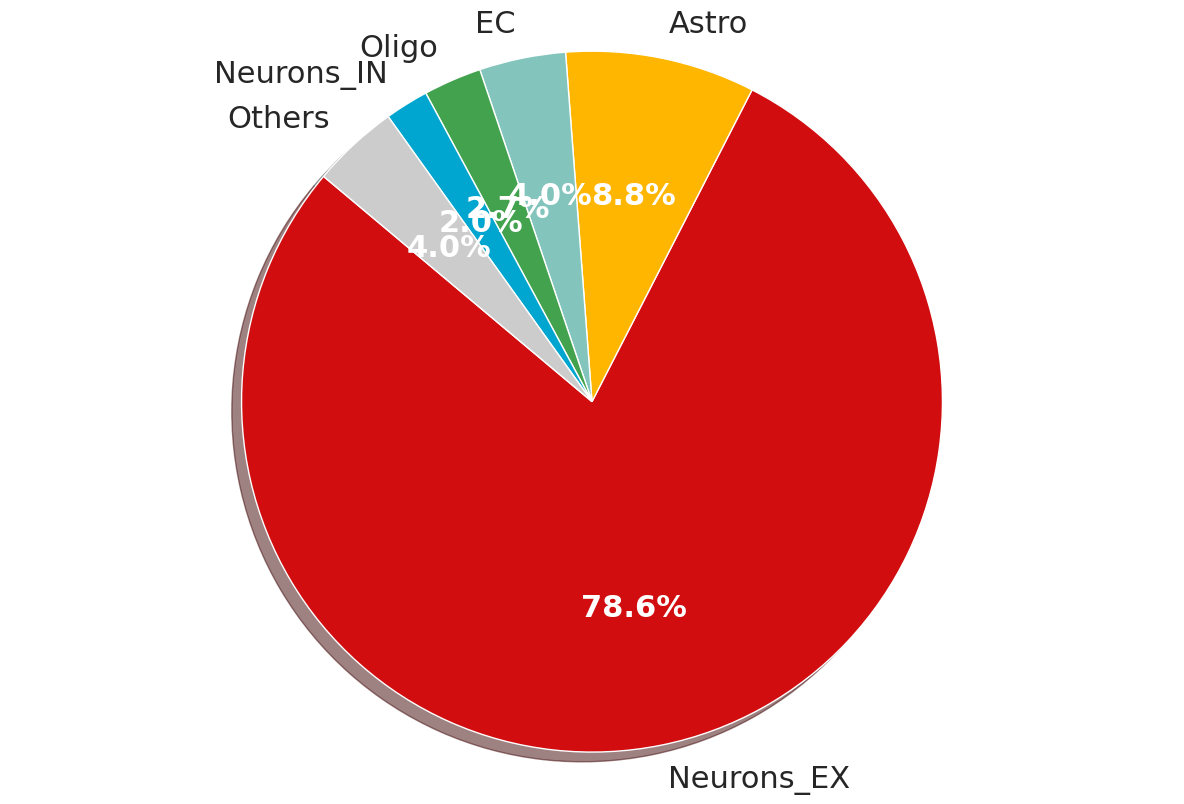

总基因数量: 10
显示的主要基因数量: 5
合并的其他基因数量: 5
其他基因总占比: 4.01%


In [24]:

# 
color_mapping = {
    'Neurons_EX': '#D10D0F',
    'Neurons_IN': "#00A6D0",
    'Astro': "#FFB600",
    'Oligo': "#42A24E",
    'OPC': '#0F7240',
    'Micro': '#507BA8',
    'FBs': '#354C85',
    'EC': '#83C5BD',
    'Epen': '#5d2b84',
    'Peri': '#BBB8D7'
}


# 
labels = gene_percentage_df['gene'].tolist()
sizes = gene_percentage_df['percentage'].tolist()

# 
colors = [color_mapping.get(gene, '#cccccc') for gene in labels]  # 

# 
threshold = 2.0  # 

# 
main_genes = gene_percentage_df[gene_percentage_df['percentage'] >= threshold]
other_genes = gene_percentage_df[gene_percentage_df['percentage'] < threshold]

# 
main_labels = main_genes['gene'].tolist()
main_sizes = main_genes['percentage'].tolist()
main_colors = [color_mapping.get(gene, '#cccccc') for gene in main_labels]

# 
if len(other_genes) > 0:
    other_percentage = other_genes['percentage'].sum()
    main_labels.append(f'Others')
    main_sizes.append(other_percentage)
    main_colors.append('#cccccc')  # 

# 
plt.figure(figsize=(12, 8))
wedges, texts, autotexts = plt.pie(
    main_sizes,
    labels=main_labels,
    colors=main_colors,
    autopct='%1.1f%%',
    startangle=140,
    shadow=True,
    textprops={'fontsize': 22}
)

# 
for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')

plt.axis('equal')
plt.tight_layout()

# 
plt.savefig('/mnt/e/AD_analysis/niche2 EC_pie_chart.png',########改这里
            dpi=500, bbox_inches='tight', facecolor='white')
plt.show()

# 

In [59]:
#adata.write("/mnt/e/Xenium/LEC_NMF_CN.h5ad")

In [8]:
# 
results_fdr = compare_neighborhood_expression_corrected(
    adata, 
    group_col='Hip', 
    group_a='niche_2',    #
    group_b='niche_3',
    correction_method='fdr_bh',  # 
    pval_threshold=0.01,        # 
    min_expr_cells=10           # 
)


In [9]:

print(f"FDR校正后显著基因数: {len(results_fdr['significant_genes'])}")

top_genes = results_fdr['significant_genes'].sort_values('adj_p_value').head(10)
all_gene = results_fdr['significant_genes'].sort_values('adj_p_value')

all_gene.to_csv('/mnt/e/AD_analysis/neiborhood diff gene.csv', index=False)
top_genes

FDR校正后显著基因数: 8


,gene,niche_2_vs_niche_3_log2FC,abs_log2FC,p_value,adj_p_value,significant,valid_gene,mean_expr_a,mean_expr_b,expr_ratio
6,Neurons_IN,0.005184,0.005184,5.589487e-309,5.589487e-308,True,True,0.020042,0.014858,1.348802
1,EC,0.005239,0.005239,1.489341e-104,7.446703e-104,True,True,0.035595,0.030356,1.172544
5,Neurons_EX,-0.007458,0.007458,9.305453e-45,3.101818e-44,True,True,0.791968,0.799425,0.990670
0,Astro,0.003304,0.003304,1.767661e-39,4.419152e-39,True,True,0.087879,0.084575,1.039048
3,FBs,-0.001108,0.001108,6.855482e-37,1.371096e-36,True,True,0.001601,0.002710,0.590807
2,Epen,-0.003498,0.003498,5.390807e-26,8.984678e-26,True,True,0.000526,0.004024,0.130690
8,Oligo,-0.001756,0.001756,2.453927e-17,3.505610e-17,True,True,0.026631,0.028387,0.938108
4,Micro,-0.000128,0.000128,2.964052e-06,3.705064e-06,True,True,0.018410,0.018538,0.993058


In [52]:
#
adata2 = adata#######

adata2= sm.tl.spatial_count(adata2, phenotype='Cell_Anno', #细胞
                            method='radius', radius=50, label='spatial_count',imageid='batch')
adata2 = ad.AnnData(X=adata2.uns['spatial_count'],obs = adata2.obs,uns = adata2.uns)

adata2.var.index = adata2.uns['spatial_count'].columns

adata2.uns['spatial_count'] = adata2.uns['spatial_count'].loc[adata.obs.index,:]


Identifying neighbours within 50 pixels of every cell


In [74]:
adata2.uns['spatial_count'] 

neighbour_phenotype,Astro,EC,Epen,FBs,Micro,Neurons_EX,Neurons_IN,OPC,Oligo,Peri
abaojamg-1_IWD,0.027397,0.041096,0.0,0.0,0.027397,0.863014,0.013699,0.013699,0.013699,0.000000
abapbpgb-1_IWD,0.000000,0.025641,0.0,0.0,0.000000,0.948718,0.025641,0.000000,0.000000,0.000000
abapdpam-1_IWD,0.000000,0.012048,0.0,0.0,0.000000,0.951807,0.024096,0.000000,0.000000,0.012048
abbbdhbo-1_IWD,0.200000,0.000000,0.0,0.0,0.000000,0.800000,0.000000,0.000000,0.000000,0.000000
abbbihlg-1_IWD,0.047619,0.023810,0.0,0.0,0.000000,0.928571,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...
oihfipai-1_CWD,0.092784,0.020619,0.0,0.0,0.000000,0.814433,0.020619,0.010309,0.041237,0.000000
oihfmidd-1_CWD,0.075269,0.032258,0.0,0.0,0.032258,0.817204,0.032258,0.000000,0.010753,0.000000
oihfnhjp-1_CWD,0.024691,0.012346,0.0,0.0,0.012346,0.864198,0.086420,0.000000,0.000000,0.000000
oihfomnh-1_CWD,0.000000,0.013889,0.0,0.0,0.013889,0.958333,0.013889,0.000000,0.000000,0.000000


找到 3456 个EC细胞
niche_2组EC细胞数: 189
niche_3组EC细胞数: 112


/tmp/ipykernel_847/874881744.py:139: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_847/874881744.py:144: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_847/874881744.py:148: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_847/874881744.py:139: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_847/874881744.py:144: FutureWarning:



Passing `palette` without assigning `hue` is deprecated a

✨ 图片已保存到: /mnt/e/AD_analysis/EC_niche_2_vs_niche_3_neighborhood.pdf
🎯 最显著基因: EC (p=0.002044)


/root/miniconda3/envs/scimap/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning:

Glyph 10024 (\N{SPARKLES}) missing from font(s) DejaVu Sans.

/root/miniconda3/envs/scimap/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning:

Glyph 127800 (\N{CHERRY BLOSSOM}) missing from font(s) DejaVu Sans.

/root/miniconda3/envs/scimap/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning:

Glyph 127872 (\N{RIBBON}) missing from font(s) DejaVu Sans.

/root/miniconda3/envs/scimap/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning:

Glyph 32454 (\N{CJK UNIFIED IDEOGRAPH-7EC6}) missing from font(s) DejaVu Sans.

/root/miniconda3/envs/scimap/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning:

Glyph 32990 (\N{CJK UNIFIED IDEOGRAPH-80DE}) missing from font(s) DejaVu Sans.

/root/miniconda3/envs/scimap/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning:

Glyph 22312 (\N{CJK UNIF

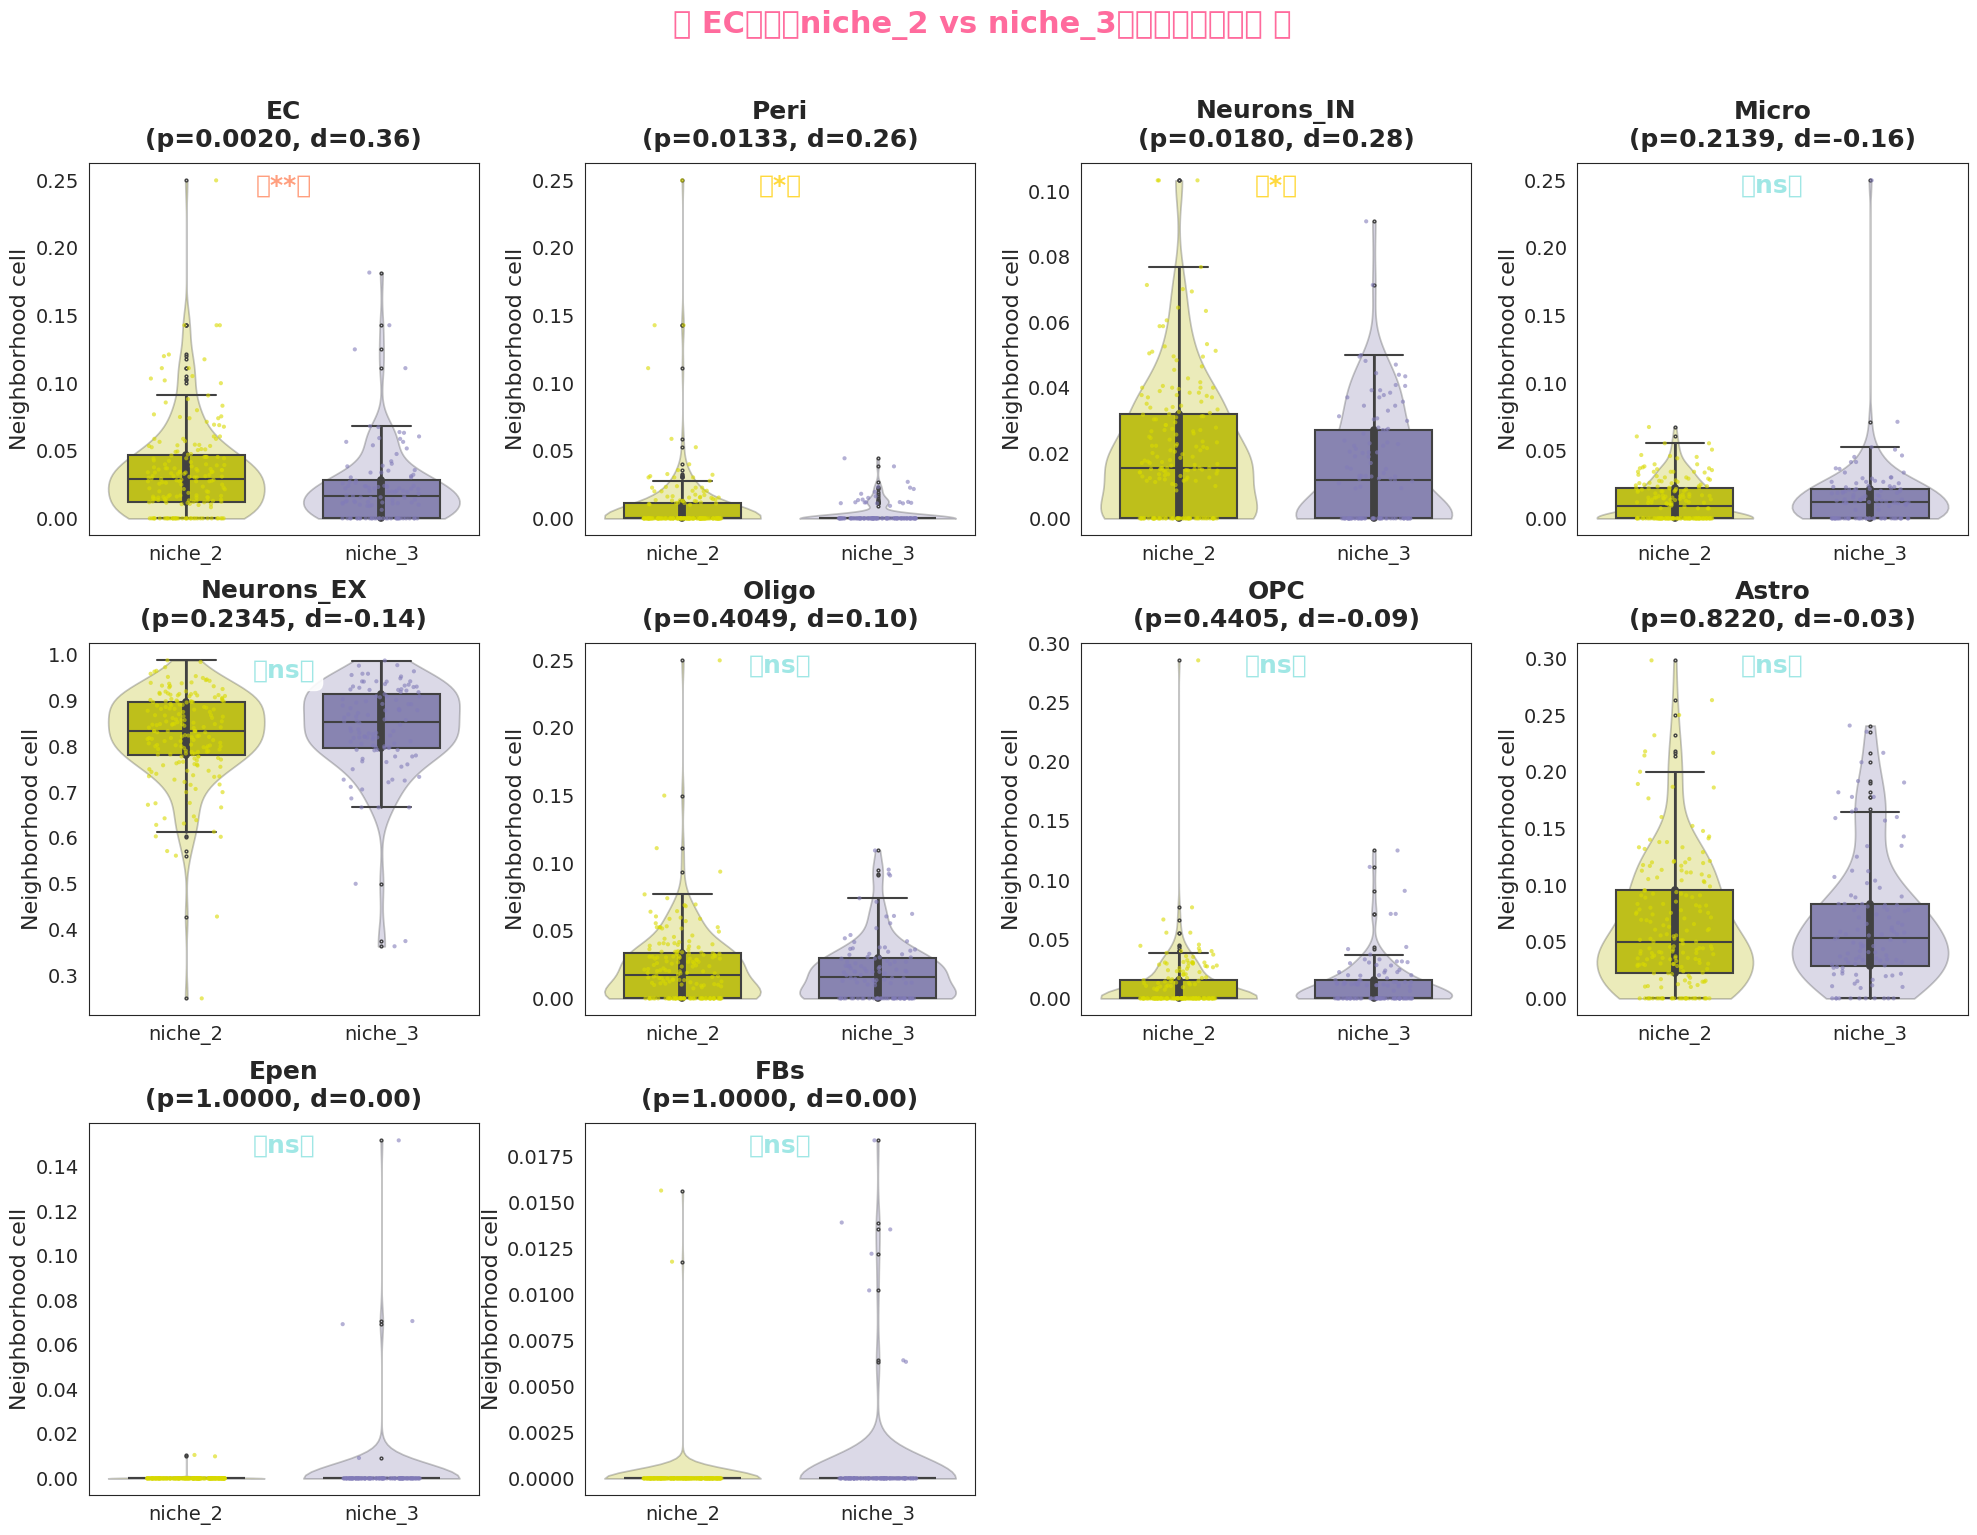

In [94]:
#
results = compare_neighborhood_cell(
    adata,
    niche_col='Hip',
    group_a='niche_2', 
    group_b='niche_3',
    target_celltype='EC',
    colors=['#d9da00', '#827cb9'],  # 
    top_genes=20,
    font_size=16,  # 
    title_size=18,  # 
    save_path='/mnt/e/EC_niche_2_vs_niche_3_neighborhood.pdf'
)
# 
top_gene = results['top_statistics'].iloc[0]['gene']
print(f"🎯 最显著基因: {top_gene} (p={results['top_statistics'].iloc[0]['p_value']:.6f})")

In [68]:
def compare_neighborhood_expression_corrected(adata, group_col, group_a, group_b, 
                                            neighborhood_matrix_key='spatial_count',
                                            min_cells=10, pval_threshold=0.05,
                                            correction_method='fdr_bh', min_expr_cells=5):
 
    
    # 
    if group_col not in adata.obs.columns:
        raise ValueError(f"列 '{group_col}' 不存在于 adata.obs")
    
    if neighborhood_matrix_key not in adata.uns:
        raise ValueError(f"邻域矩阵 '{neighborhood_matrix_key}' 不存在于 adata.uns")
    
    # 
    adata.obs[group_col] = adata.obs[group_col].astype('category')
    group_a_idx = adata.obs[adata.obs[group_col] == group_a].index
    group_b_idx = adata.obs[adata.obs[group_col] == group_b].index
    
    if len(group_a_idx) < min_cells or len(group_b_idx) < min_cells:
        raise ValueError(f"至少一组细胞数少于 {min_cells}")
    
    # 
    neighborhood_matrix = adata.uns[neighborhood_matrix_key]
    
    # 
    neighborhood_a = neighborhood_matrix.loc[group_a_idx].mean(axis=0)
    neighborhood_b = neighborhood_matrix.loc[group_b_idx].mean(axis=0)
    neighborhood_diff = neighborhood_a - neighborhood_b
    
    # 
    expr_a = adata[group_a_idx, :].X
    expr_b = adata[group_b_idx, :].X
    
    if hasattr(expr_a, 'toarray'):
        expr_a = expr_a.toarray()
        expr_b = expr_b.toarray()
    
    gene_diff = expr_a.mean(axis=0) - expr_b.mean(axis=0)
    
    #
    from statsmodels.stats.multitest import multipletests
    
    p_values = []
    valid_genes = []
    
    for i, gene in enumerate(adata.var_names):
        expr_a_gene = expr_a[:, i]
        expr_b_gene = expr_b[:, i]
        
        # 
        n_expr_a = np.sum(expr_a_gene > 0)
        n_expr_b = np.sum(expr_b_gene > 0)
        
        # 
        if n_expr_a < min_expr_cells and n_expr_b < min_expr_cells:
            p_values.append(1.0)
            valid_genes.append(False)
            continue
        
        valid_genes.append(True)
        
        try:
            # 
            u_stat, p_val = stats.mannwhitneyu(expr_a_gene, expr_b_gene, alternative='two-sided')
            p_values.append(p_val)
        except:
            p_values.append(1.0)
    
    # 
    valid_p_values = [p for i, p in enumerate(p_values) if valid_genes[i]]
    
    if len(valid_p_values) > 0:
        # 
        if correction_method == 'fdr_bh':
            # 
            reject, adj_p, _, _ = multipletests(valid_p_values, alpha=pval_threshold, method='fdr_bh')
        elif correction_method == 'bonferroni':
            #
            reject, adj_p, _, _ = multipletests(valid_p_values, alpha=pval_threshold, method='bonferroni')
        elif correction_method == 'fdr_by':
            # 
            reject, adj_p, _, _ = multipletests(valid_p_values, alpha=pval_threshold, method='fdr_by')
        else:
            raise ValueError("不支持的校正方法")
        
        # 
        full_adj_p = np.ones(len(p_values))
        valid_idx = 0
        for i, is_valid in enumerate(valid_genes):
            if is_valid:
                full_adj_p[i] = adj_p[valid_idx]
                valid_idx += 1
    else:
        full_adj_p = np.ones(len(p_values))
    
    # 7. 
    result_df = pd.DataFrame({
        'gene': adata.var_names,
        f'{group_a}_vs_{group_b}_log2FC': gene_diff,
        'abs_log2FC': abs(gene_diff),
        'p_value': p_values,
        'adj_p_value': full_adj_p,
        'significant': full_adj_p < pval_threshold,
        'valid_gene': valid_genes
    })
    
    # 8. 
    result_df['mean_expr_a'] = expr_a.mean(axis=0)
    result_df['mean_expr_b'] = expr_b.mean(axis=0)
    result_df['expr_ratio'] = result_df['mean_expr_a'] / (result_df['mean_expr_b'] + 1e-6)
 
    results = {
        'group_a': group_a,
        'group_b': group_b,
        'correction_method': correction_method,
        'pval_threshold': pval_threshold,
        'neighborhood_diff': neighborhood_diff,
        'expression_results': result_df,
        'significant_genes': result_df[result_df['significant']],
        'valid_genes_count': sum(valid_genes),
        'significant_count': sum(result_df['significant'])
    }
    
    return results




def compare_neighborhood_cell(adata, niche_col='Hip', group_a='niche_2', group_b='niche_3',
                              cell_anno_col='Cell_Anno', target_celltype='EC',
                              colors=['#FF9AA2', '#B5EAD7'],  # 
                              top_genes=20, figsize=(20, 15), save_path=None,
                              font_size=14, title_size=16):
 
    
    # 
    plt.style.use('default')
    sns.set_style("white")  # 
    
    #
    ec_cells = adata.obs[adata.obs[cell_anno_col] == target_celltype].index
    print(f"找到 {len(ec_cells)} 个{target_celltype}细胞")
    
    if len(ec_cells) == 0:
        raise ValueError(f"未找到{target_celltype}细胞")
    
    # 
    group_a_ec = adata.obs[(adata.obs[cell_anno_col] == target_celltype) & 
                          (adata.obs[niche_col] == group_a)].index
    group_b_ec = adata.obs[(adata.obs[cell_anno_col] == target_celltype) & 
                          (adata.obs[niche_col] == group_b)].index
    
    print(f"{group_a}组{target_celltype}细胞数: {len(group_a_ec)}")
    print(f"{group_b}组{target_celltype}细胞数: {len(group_b_ec)}")
    
    if len(group_a_ec) == 0 or len(group_b_ec) == 0:
        raise ValueError(f"至少一组{target_celltype}细胞数为0")
    
    # 
    expr_matrix = adata.X
    if hasattr(expr_matrix, 'toarray'):
        expr_matrix = expr_matrix.toarray()
    
    expr_df = pd.DataFrame(expr_matrix, index=adata.obs.index, columns=adata.var_names)
    
    # 
    genes = adata.var_names
    p_values = {}
    mean_diff = {}
    effect_size = {}
    
    for gene in genes:
        expr_a = expr_df.loc[group_a_ec, gene]
        expr_b = expr_df.loc[group_b_ec, gene]
        
        # 
        if np.sum(expr_a > 0) < 5 or np.sum(expr_b > 0) < 5:
            p_values[gene] = 1.0
            mean_diff[gene] = 0
            effect_size[gene] = 0
            continue
        
        # 
        mean_a = expr_a.mean()
        mean_b = expr_b.mean()
        mean_diff[gene] = mean_a - mean_b
        
        try:
            t_stat, p_val = stats.ttest_ind(expr_a, expr_b, equal_var=False)
            p_values[gene] = p_val
            
            pooled_std = np.sqrt((expr_a.std()**2 + expr_b.std()**2) / 2)
            if pooled_std > 0:
                effect_size[gene] = (mean_a - mean_b) / pooled_std
            else:
                effect_size[gene] = 0
        except:
            p_val = 1.0
            p_values[gene] = p_val
            effect_size[gene] = 0
    
    # 
    result_df = pd.DataFrame({
        'gene': genes,
        f'{group_a}_mean': [expr_df.loc[group_a_ec, gene].mean() for gene in genes],
        f'{group_b}_mean': [expr_df.loc[group_b_ec, gene].mean() for gene in genes],
        'mean_difference': [mean_diff[gene] for gene in genes],
        'p_value': [p_values[gene] for gene in genes],
        'effect_size': [effect_size[gene] for gene in genes]
    })
    
    result_df_sorted = result_df.sort_values('p_value')
    
    # 
    top_genes_list = result_df_sorted.head(top_genes)['gene'].tolist()
    
    n_cols = 4
    n_rows = (len(top_genes_list) + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=figsize)
    axes = axes.flatten() if n_rows > 1 else [axes]
    
    for i, gene in enumerate(top_genes_list):
        if i >= len(axes):
            break
            
        # 
        expr_a = expr_df.loc[group_a_ec, gene]
        expr_b = expr_df.loc[group_b_ec, gene]
        p_val = p_values[gene]
        effect = effect_size[gene]
        
        # 
        data_to_plot = pd.DataFrame({
            'Group': [group_a] * len(expr_a) + [group_b] * len(expr_b),
            'Expression': np.concatenate([expr_a, expr_b])
        })
        
        # 
        sns.boxplot(data=data_to_plot, x='Group', y='Expression', 
                   palette=colors, width=0.6, ax=axes[i], 
                   fliersize=2, linewidth=1.5)
        
        # 
        sns.violinplot(data=data_to_plot, x='Group', y='Expression', 
                      palette=colors, alpha=0.3, ax=axes[i], cut=0)
        
        # 
        sns.stripplot(data=data_to_plot, x='Group', y='Expression', 
                     palette=colors, alpha=0.6, size=3, jitter=0.2, ax=axes[i])
        
        # 
        if p_val < 0.001:
            p_text = '✨***✨'
            text_color = '#FF6B9D'
        elif p_val < 0.01:
            p_text = '✨**✨'
            text_color = '#FF9F7F'
        elif p_val < 0.05:
            p_text = '✨*✨'
            text_color = '#FFD93D'
        else:
            p_text = '🌸ns🌸'
            text_color = '#A0E7E5'
        
        # 
        y_max = max(expr_a.max(), expr_b.max())
        axes[i].text(0.5, y_max * 0.95, p_text, ha='center', va='bottom', 
                    fontsize=font_size+2, fontweight='bold', color=text_color,
                    bbox=dict(boxstyle="round,pad=0.3", facecolor='white', alpha=0.9))
        
        # 
        axes[i].set_title(f'{gene}\n(p={p_val:.4f}, d={effect:.2f})', 
                         fontsize=title_size, fontweight='bold', pad=12)
        axes[i].set_xlabel('', fontsize=font_size)
        axes[i].set_ylabel('Neighborhood cell', fontsize=font_size)
        
        #
        axes[i].tick_params(axis='both', which='major', labelsize=font_size-2)
        
        # 
        axes[i].grid(False)
        axes[i].spines['top'].set_visible(True)
        axes[i].spines['right'].set_visible(True)
        axes[i].spines['bottom'].set_visible(True)
        axes[i].spines['left'].set_visible(True)
    
    # 
    for j in range(i+1, len(axes)):
        axes[j].set_visible(False)
    
    # 
    plt.suptitle(f'🎀 {target_celltype}细胞在{group_a} vs {group_b}中的基因表达差异 🎀', 
                fontsize=title_size+4, fontweight='bold', y=1.02, color='#FF6B9D')
    plt.tight_layout()
    
    # 
    if save_path:
        plt.savefig(save_path, bbox_inches='tight', dpi=300, facecolor='white')
        print(f"✨ 图片已保存到: {save_path}")
    
    # 
    results = {
        'figure': fig,
        'all_statistics': result_df,
        'top_statistics': result_df_sorted.head(top_genes),
        'p_values': p_values,
        'mean_diff': mean_diff,
        'effect_sizes': effect_size
    }
    
    return results